# 4_2_DengueTuningOneShot
In this notebook, we work on tuning the dengue model in a "one-shot" setting. This means that we set output_chunk_length to the length of our forecast and output_chunk_shift to the gap size (15 weeks). 

In [1]:
import pandas as pd
import numpy as np
import torch 
import os
import json

from darts import TimeSeries, concatenate
from darts.utils.callbacks import TFMProgressBar
from darts.metrics import mape, smape, mse, rmse, mae, mql, ql
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing.transformers import StaticCovariatesTransformer
from sklearn.preprocessing import MinMaxScaler
import optuna
from optuna.samplers import TPESampler
from darts.models import (
    RandomForestModel,
    LinearRegressionModel,
    XGBModel,
    TFTModel,
    TiDEModel
)
from darts.utils.likelihood_models import GaussianLikelihood, PoissonLikelihood, QuantileRegression
import matplotlib.pyplot as plt
from pytorch_lightning.callbacks import Callback, EarlyStopping
import pickle
import helpers as hp

torch.set_float32_matmul_precision("medium")
pd.options.mode.copy_on_write = True
global_fit = False
include_stringency_index = False
random_seed = 20
accel = "gpu"

quantiles = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95,0.975, 0.99]

# 1. Reading in Data

In [2]:
tuning_name = "TestNotebook"
base_dir = os.getcwd()
model_input_dir = os.path.join(base_dir, "ModelInput")
tuning_dir = os.path.join(base_dir, "Dengue Tuning", tuning_name)
climate_tuning_dir = os.path.join(base_dir, "Climate Tuning", "Notebook_24_07_2025")
climate_model_name = "RandomForest"
climate_forecast_dir = os.path.join(climate_tuning_dir, climate_model_name, "Forecasts")

os.makedirs(tuning_dir, exist_ok = True)

weekly_cal = pd.read_csv(os.path.join(model_input_dir, "Calendar.csv"))
weekly_cal = weekly_cal.iloc[1:]
climate_df = pd.read_csv(os.path.join(model_input_dir, "TimeVaryingCovs.csv"))
dengue_df = pd.read_csv(os.path.join(model_input_dir, "DengueCases.csv"))

#Remove uf = "ES" since there is no dengue data for Espirito Santo
climate_df = climate_df[climate_df["uf"] != "ES"]
dengue_df = dengue_df[dengue_df["uf"] != "ES"]

dengue_df = dengue_df[["epiweek", "Year", "Week", "uf", "uf_name", "Cases"]]

In [3]:
#Read the climate forecasts
clim_forecast_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict.pkl"))
clim_forecast_log_dict = hp.load_pickle(os.path.join(climate_forecast_dir, "forecast_dict_log.pkl"))

In [4]:
clim_tuning_config = hp.read_json(os.path.join(climate_tuning_dir,"tuning_details.json"))
clim_var_names = clim_tuning_config["clim_var_names"]

#If boolean says we should include stringency index, then we add it into the climate variable names
if include_stringency_index:
    clim_var_names.append("StringencyIndex")

In [5]:
set_info = weekly_cal[["epiweek", "Year", "Week", "WeekStart", "WeekMid", "WeekEnd"]]


#Set up all the set information for splitting the dengue and climate data

#For tuning training 1a,b,c - val1a,b,c
set_info["den_train1a"] = set_info["epiweek"] <= 201825
set_info["den_train1b"] = set_info["epiweek"] <= 201925
set_info["den_train1c"] = set_info["epiweek"] <= 202025

set_info["den_gap1a"] = (set_info["epiweek"] >= 201826) & (set_info["epiweek"] <= 201840)
set_info["den_gap1b"] = (set_info["epiweek"] >= 201926) & (set_info["epiweek"] <= 201940)
set_info["den_gap1c"] = (set_info["epiweek"] >= 202026) & (set_info["epiweek"] <= 202040)

set_info["den_val1a"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
set_info["den_val1b"] = (set_info["epiweek"] >= 201941) & (set_info["epiweek"] <= 202040)
set_info["den_val1c"] = (set_info["epiweek"] >= 202041) & (set_info["epiweek"] <= 202140)

set_info["den_ex"] = (set_info["epiweek"] >= 202141) & (set_info["epiweek"] <= 202225)

#Train - Val - Test for model evaluation
set_info["den_train1"] = set_info["epiweek"] <= 202110
set_info["den_train2"] = set_info["epiweek"] <= 202210
set_info["den_train3"] = set_info["epiweek"] <= 202310

set_info["den_val1"] = (set_info["epiweek"] >= 202126) & (set_info["epiweek"] <= 202225)
set_info["den_val2"] = (set_info["epiweek"] >= 202226) & (set_info["epiweek"] <= 202325)
set_info["den_val3"] = (set_info["epiweek"] >= 202326) & (set_info["epiweek"] <= 202425)

set_info["den_targ1"] = (set_info["epiweek"] >= 202241) & (set_info["epiweek"] <= 202340)
set_info["den_targ2"] = (set_info["epiweek"] >= 202341) & (set_info["epiweek"] <= 202440)
set_info["den_targ3"] = (set_info["epiweek"] >= 202441) & (set_info["epiweek"] <= 202540)

# set_info["clim_test"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
# set_info["clim_test_input"] = set_info["epiweek"] <= 201825


In [6]:
uf_list = climate_df["uf"].unique()
uf_mapper = climate_df[["uf", "uf_name"]].copy().drop_duplicates()
uf_dict = dict(zip(uf_mapper["uf"], uf_mapper["uf_name"]))
uf_name_list = [uf_dict[curr_uf] for curr_uf in uf_list]

# 2. Data Preparation

In [7]:
#Log transformed climate (just the precipitation columns)
log_trans_cols = ["precip_min", "precip_med", "precip_max"]
proc_climate_df = hp.transform_df_cols(climate_df, log_trans_cols, np.log1p)

#Log transformed dengue cases
proc_dengue_df = hp.transform_df_cols(dengue_df, ["Cases"], np.log1p)

In [8]:
#Create all the TimeSeries objects we need for tuning first
group_col = "uf"

#Dengue case TimeSeries
train1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

val1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")

#Log transformed version of the cases TimeSeries for actual training
train1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

gap1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1a")
gap1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1b")
gap1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1c")

val1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")

#Climate values to use as covariates 
clim_train1a_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1a")
clim_train1b_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1b")
clim_train1c_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_train1c")

#These are just for checking, and won't be used in the actual forecasting since we use forecasted variables in the validation set
clim_val1a_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1a")
clim_val1b_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1b")
clim_val1c_log = hp.create_ts_list(proc_climate_df, clim_var_names, group_col, uf_list, set_info = set_info, set_column = "den_val1c")

#Get the forecasts over the validation set to be used as future covariates
clim_preds_1a_log = clim_forecast_log_dict["clim_preds_1a"]
clim_preds_1b_log = clim_forecast_log_dict["clim_preds_1b"]
clim_preds_1c_log = clim_forecast_log_dict["clim_preds_1c"]


#Processing with COVID-19 stringency index (optional)
def intersect_stack(curr_shorter, curr_longer): 
    to_stack = curr_longer.slice_intersect(curr_shorter)
    return curr_shorter.stack(to_stack)

if include_stringency_index:
    #If including the StringencyIndex, then should at it to the climate forecasts
    #Since there is no StringencyIndex forecasting model, we assume it is 0 in forecasts
    temp_cal = weekly_cal.copy()
    temp_cal["WeekStart"] = pd.to_datetime(temp_cal["WeekStart"], format = "%Y-%m-%d")
    temp_cal = temp_cal.set_index("WeekStart")
    zero_series = TimeSeries.from_times_and_values(
        times = temp_cal.index,
        values = np.zeros(len(temp_cal)),
        columns=["StringencyIndex"]
    )
    
    #Add the zero series into the TimeSeries with predicted climate
    clim_preds_1a_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1a_log]
    clim_preds_1b_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1b_log]
    clim_preds_1c_log = [intersect_stack(curr_series, zero_series) for curr_series in clim_preds_1c_log]

## 2.1 Add Static Covariates

In [9]:
stat_covs = pd.read_csv(os.path.join(model_input_dir, "StaticCovs.csv"))
stat_covs_names = stat_covs.columns[2:]

#generate min-max scaled version of the static covariates
stat_cov_scaler = MinMaxScaler()
stat_cov_scaler.fit(stat_covs[stat_covs_names])
stat_covs_vals_s = pd.DataFrame(stat_cov_scaler.transform(stat_covs[stat_covs_names]), columns = stat_covs_names)
stat_covs_s = pd.concat([stat_covs[["uf", "uf_name"]], stat_covs_vals_s], axis = 1)


In [10]:
train1a_log_sc = hp.add_stat_covs(train1a_log, stat_covs_s, uf_list, stat_covs_names)
train1b_log_sc = hp.add_stat_covs(train1b_log, stat_covs_s, uf_list, stat_covs_names)
train1c_log_sc = hp.add_stat_covs(train1c_log, stat_covs_s, uf_list, stat_covs_names)

# val1a_log_sc = hp.add_stat_covs(val1a_log, stat_covs_s, uf_list, stat_covs_names)
# val1b_log_sc = hp.add_stat_covs(val1b_log, stat_covs_s, uf_list, stat_covs_names)
# val1c_log_sc = hp.add_stat_covs(val1c_log, stat_covs_s, uf_list, stat_covs_names)

## 2.3 Rescaling TimeSeries data

In [11]:
#Rescale the cases and the covariates
den_tune_scaler = Scaler(global_fit = global_fit)
clim_tune_scaler = Scaler(global_fit = global_fit)

#Fit the scalers to the training sets from the first folds
den_tune_scaler.fit(train1a_log_sc)
clim_tune_scaler.fit(clim_train1a_log)

#Generate the scaled TimeSeries
train1a_log_sc_s = den_tune_scaler.transform(train1a_log_sc)
train1b_log_sc_s = den_tune_scaler.transform(train1b_log_sc)
train1c_log_sc_s = den_tune_scaler.transform(train1c_log_sc)

gap1a_log_s = den_tune_scaler.transform(gap1a_log)
gap1b_log_s = den_tune_scaler.transform(gap1b_log)
gap1c_log_s = den_tune_scaler.transform(gap1c_log)

val1a_log_s = den_tune_scaler.transform(val1a_log)
val1b_log_s = den_tune_scaler.transform(val1b_log)
val1c_log_s = den_tune_scaler.transform(val1c_log)


#Scaled climate covariates
clim_train1a_log_s = clim_tune_scaler.transform(clim_train1a_log)
clim_train1b_log_s = clim_tune_scaler.transform(clim_train1b_log)
clim_train1c_log_s = clim_tune_scaler.transform(clim_train1c_log)

clim_preds_1a_log_s = clim_tune_scaler.transform(clim_preds_1a_log)
clim_preds_1b_log_s = clim_tune_scaler.transform(clim_preds_1b_log)
clim_preds_1c_log_s = clim_tune_scaler.transform(clim_preds_1c_log)

#Merge the training and validation covariates to be passed into the predict function for validation loss evaluation
clim_train_val1a_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1a_log_s, clim_preds_1a_log_s)]
clim_train_val1b_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1b_log_s, clim_preds_1b_log_s)]
clim_train_val1c_log_s =  [concatenate([curr_train, curr_val]) for curr_train, curr_val in zip(clim_train1c_log_s, clim_preds_1c_log_s)]

# 3. Modelling
At this point, we have all the data prepared and we can start the model tuning process.

## 3.1 Model Creation
First, we create a model creation function that creates a Darts model based on input hyperparameters.

In [12]:
gap_length = 15
val_base_length = 53
forecast_length = gap_length + val_base_length

In [13]:
def build_tft_model(model_name, batch_size, input_chunk_length, output_chunk_length, hidden_size, hidden_continuous_size, lstm_layers, num_attention_heads, dropout, learning_rate, output_chunk_shift = 0):
    torch.manual_seed(random_seed)
    curr_encoders = {"datetime_attribute": {"future": ["month", "year"]}, 
                    "transformer": Scaler()}
    early_stopper = EarlyStopping("val_loss", min_delta = 0.0001, patience = 8)

    curr_model = TFTModel(
        model_name = model_name,
        batch_size = batch_size,
        input_chunk_length = input_chunk_length,
        output_chunk_length = output_chunk_length,
        output_chunk_shift = output_chunk_shift,
        hidden_size = hidden_size,
        hidden_continuous_size = hidden_continuous_size,
        lstm_layers = lstm_layers,
        num_attention_heads = num_attention_heads,
        dropout = dropout,
        n_epochs = 100,
        add_encoders = curr_encoders,
        optimizer_kwargs = {"lr": learning_rate},
        pl_trainer_kwargs = {"accelerator": accel, "callbacks": [early_stopper]},
        show_warnings = True,
        save_checkpoints = True,
        force_reset = True,
        random_state = random_seed
    )
    return curr_model

In [14]:
#Some params from previous work, only for testing not actual use
best_params = {'batch_size': 16,
 'input_chunk_length': 200,
 'hidden_size': 64,
 'lstm_layers': 2,
 'num_attention_heads': 2,
 'dropout': 0.24801221773916896,
 'learning_rate': 0.0002739692796283639}

In [15]:
model_name = "TestOneShot"
batch_size = best_params["batch_size"]
input_chunk_length = best_params["input_chunk_length"]
hidden_size = best_params["hidden_size"] 
lstm_layers = best_params["lstm_layers"]
num_attention_heads = best_params["num_attention_heads"]
dropout = best_params["dropout"]
learning_rate = best_params["learning_rate"]

output_chunk_length = val_base_length
output_chunk_shift = gap_length 

curr_model = build_tft_model(model_name = model_name,
                             batch_size = batch_size,
                             input_chunk_length = input_chunk_length,
                             output_chunk_length = output_chunk_length, 
                             output_chunk_shift = output_chunk_shift,
                             hidden_size = hidden_size,
                             hidden_continuous_size = hidden_size,
                             lstm_layers = lstm_layers,
                             num_attention_heads = num_attention_heads,
                             dropout = dropout,
                             learning_rate = learning_rate
                            )


In [21]:
#Dynamic validation set generation - add the last input_chunk_length + gap_length data points from training set into the validation set
dyn_val1a_log_sc_s = [concatenate([curr_train[-(input_chunk_length + 1):], curr_gap, curr_val]) for curr_train, curr_gap, curr_val in zip(train1a_log_sc_s, gap1a_log_s, val1a_log_s)]
dyn_val1b_log_sc_s = [concatenate([curr_train[-(input_chunk_length + 1):], curr_gap, curr_val]) for curr_train, curr_gap, curr_val in zip(train1b_log_sc_s, gap1b_log_s, val1b_log_s)]
dyn_val1c_log_sc_s = [concatenate([curr_train[-(input_chunk_length + 1):], curr_gap, curr_val]) for curr_train, curr_gap, curr_val in zip(train1c_log_sc_s, gap1c_log_s, val1c_log_s)]

In [22]:
curr_model.fit(series = train1a_log_sc_s, 
               val_series = dyn_val1a_log_sc_s, 
               future_covariates = clim_train_val1a_log_s, 
               val_future_covariates = clim_train_val1a_log_s, 
               dataloader_kwargs = {"num_workers": 8, "persistent_workers": True})

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

   | Name                              | Type                             | Params | Mode 
------------------------------------------------------------------------------------------------
0  | train_metrics                     | MetricCollection                 | 0      | train
1  | val_metrics                       | MetricCollection                 | 0      | train
2  | input_embeddings                  | _MultiEmbedding                  | 0      | train
3  | static_covariates_vsn             | _VariableSelectionNetwork        | 268 K  | train
4  | encoder_vsn                       | _VariableSelectionNetwork        | 269 K  | train
5  | decoder_vsn                       | _VariableSelectionNetwork        | 250 K  | train
6  | static_context_grn                | _GatedResidualNetwork            | 16.8 K | train
7  | static_cont

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (15 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

TFTModel(output_chunk_shift=15, hidden_size=64, lstm_layers=2, num_attention_heads=2, full_attention=False, feed_forward=GatedResidualNetwork, dropout=0.24801221773916896, hidden_continuous_size=64, categorical_embedding_sizes=None, add_relative_index=False, loss_fn=None, likelihood=None, norm_type=LayerNorm, use_static_covariates=True, model_name=TestOneShot, batch_size=16, input_chunk_length=200, output_chunk_length=53, n_epochs=100, add_encoders={'datetime_attribute': {'future': ['month', 'year']}, 'transformer': Scaler}, optimizer_kwargs={'lr': 0.0002739692796283639}, pl_trainer_kwargs={'accelerator': 'gpu', 'callbacks': [<pytorch_lightning.callbacks.early_stopping.EarlyStopping object at 0x00000225AE1B3150>]}, show_warnings=True, save_checkpoints=True, force_reset=True, random_state=20)

In [23]:
best_model = curr_model.load_from_checkpoint(model_name, best = True)

In [24]:
val1a_predict_log_s = best_model.predict(series = train1a_log_sc_s, future_covariates = clim_train_val1a_log_s, n = val_base_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})
val1b_predict_log_s = best_model.predict(series = train1b_log_sc_s, future_covariates = clim_train_val1b_log_s, n = val_base_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})
val1c_predict_log_s = best_model.predict(series = train1c_log_sc_s, future_covariates = clim_train_val1c_log_s, n = val_base_length, num_samples = 100, dataloader_kwargs = {"num_workers": 4, "persistent_workers": True})

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [25]:
val1a_predict = hp.return_to_nat_scale(val1a_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)
val1b_predict = hp.return_to_nat_scale(val1b_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)
val1c_predict = hp.return_to_nat_scale(val1c_predict_log_s, ["Cases"], den_tune_scaler, trans_func = np.expm1)

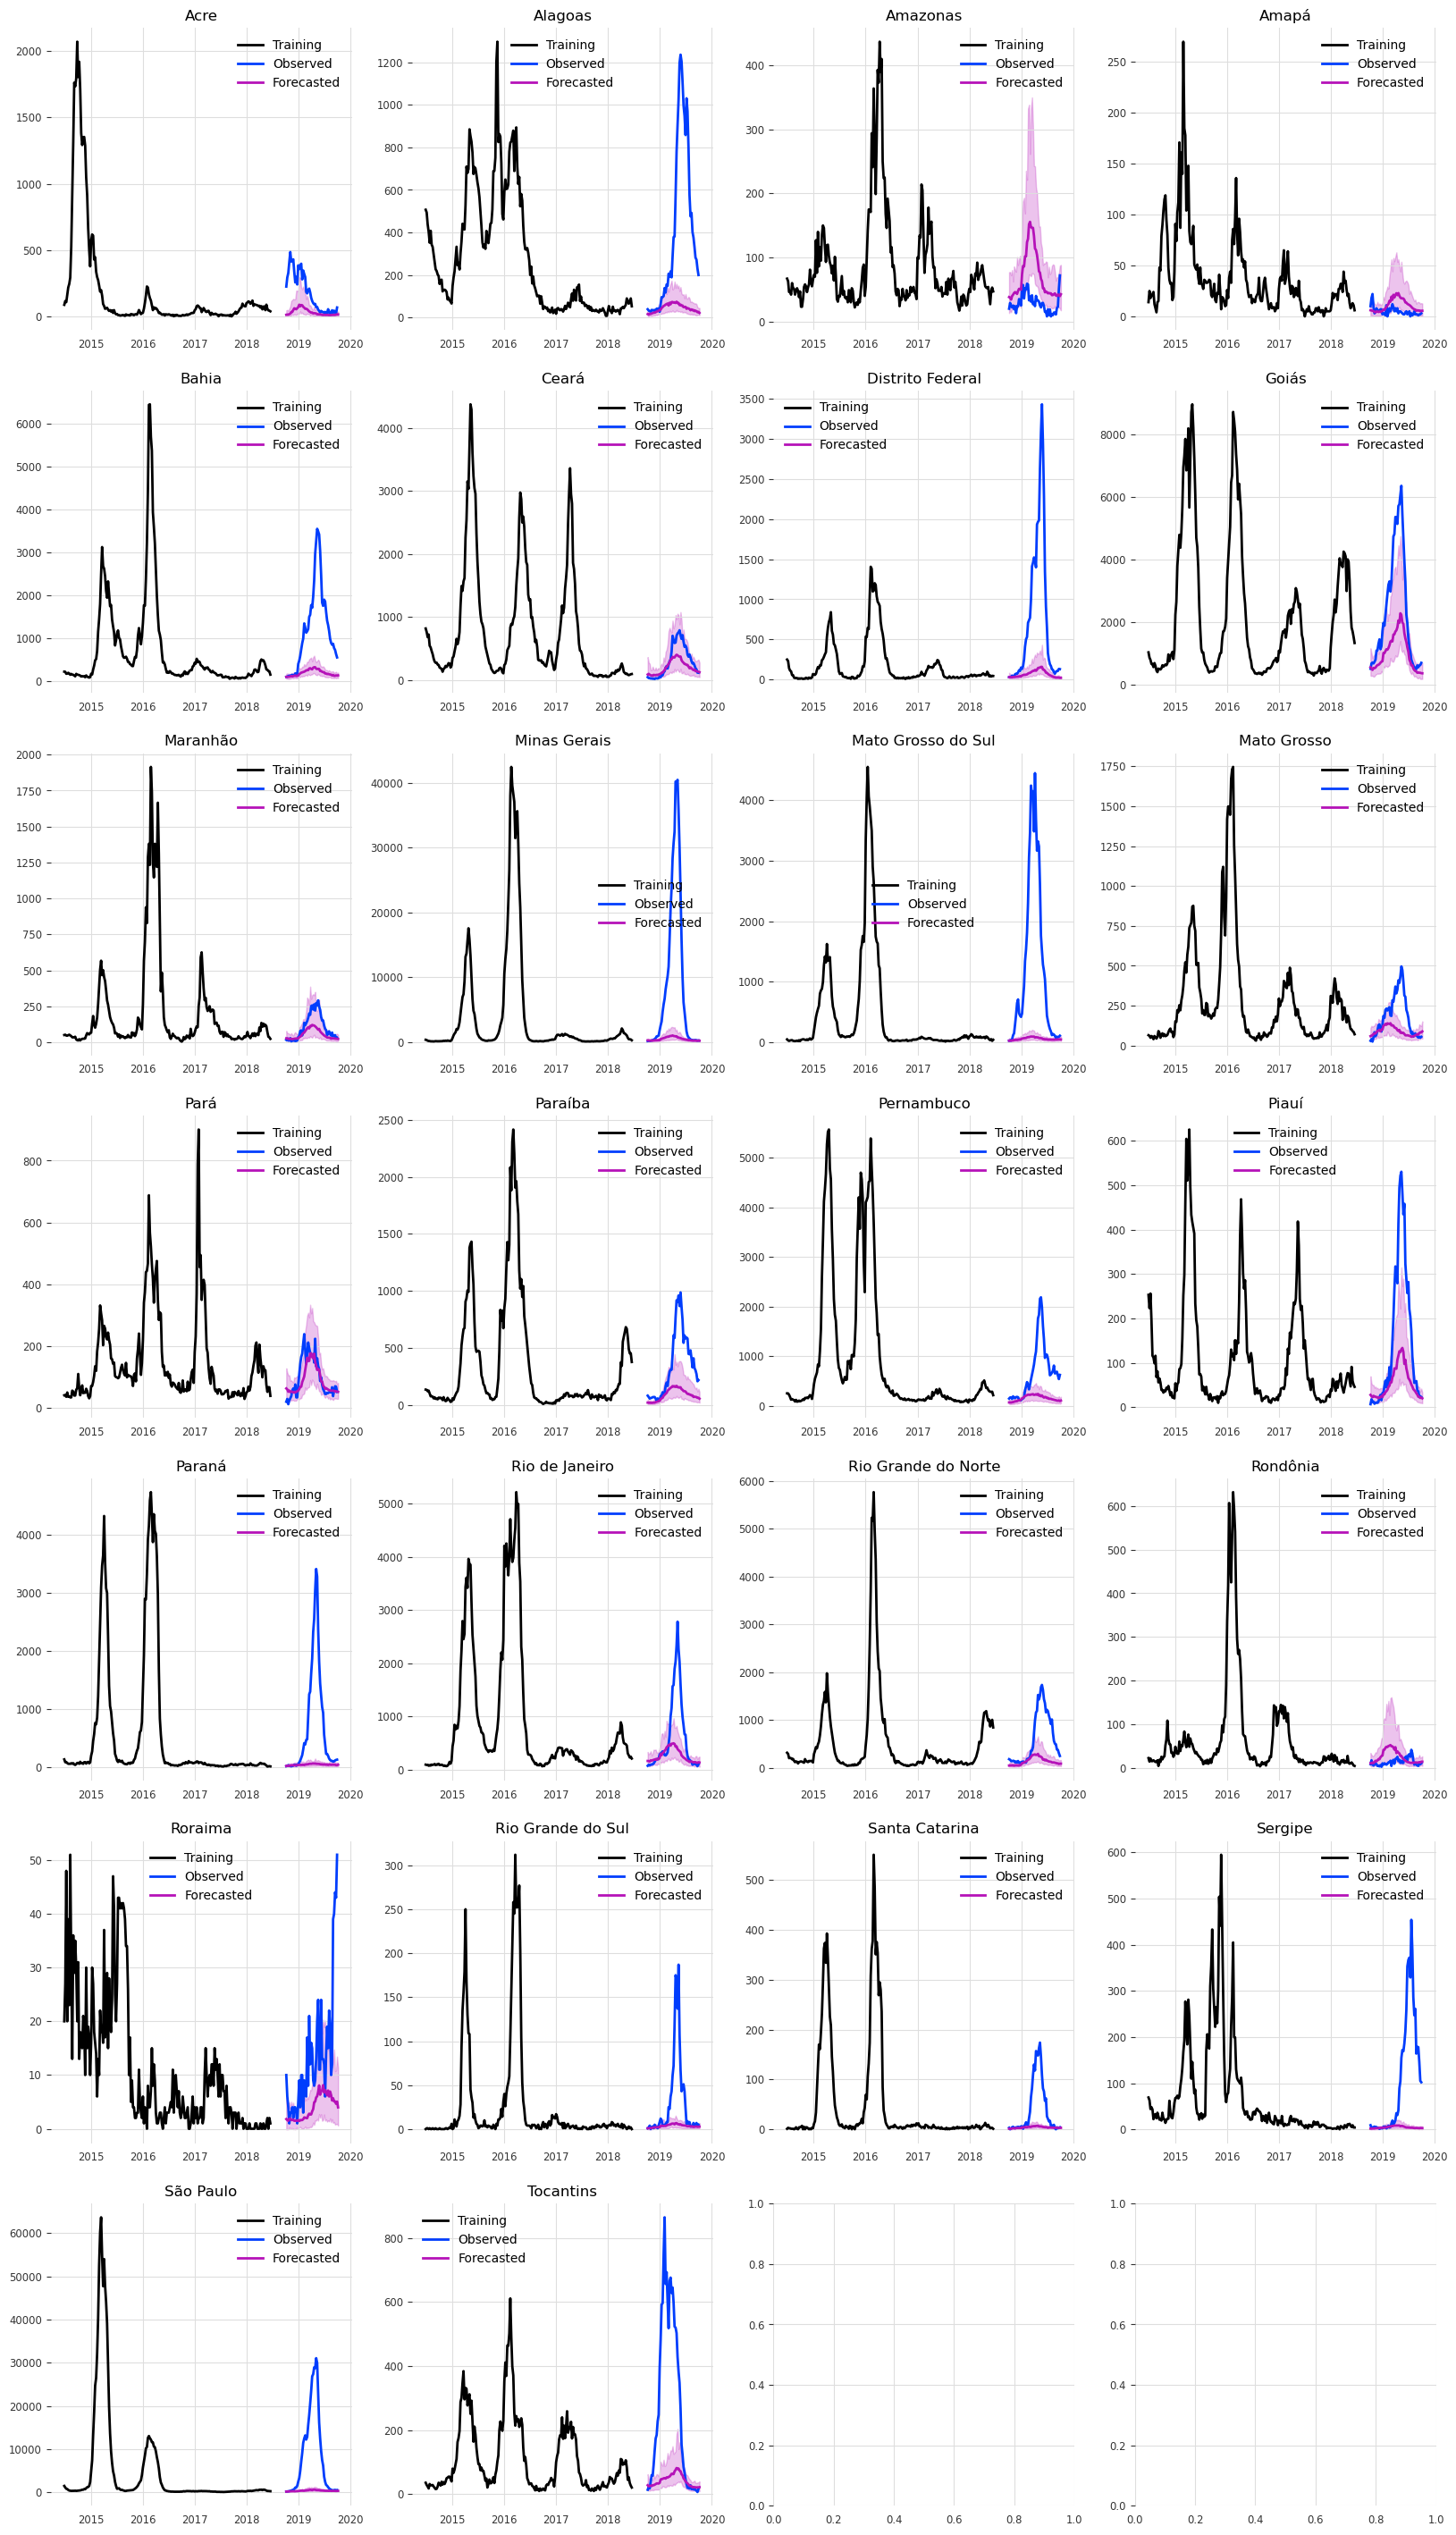

In [29]:
hp.generate_preds_obs_den_plot(train1a, val1a, val1a_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)

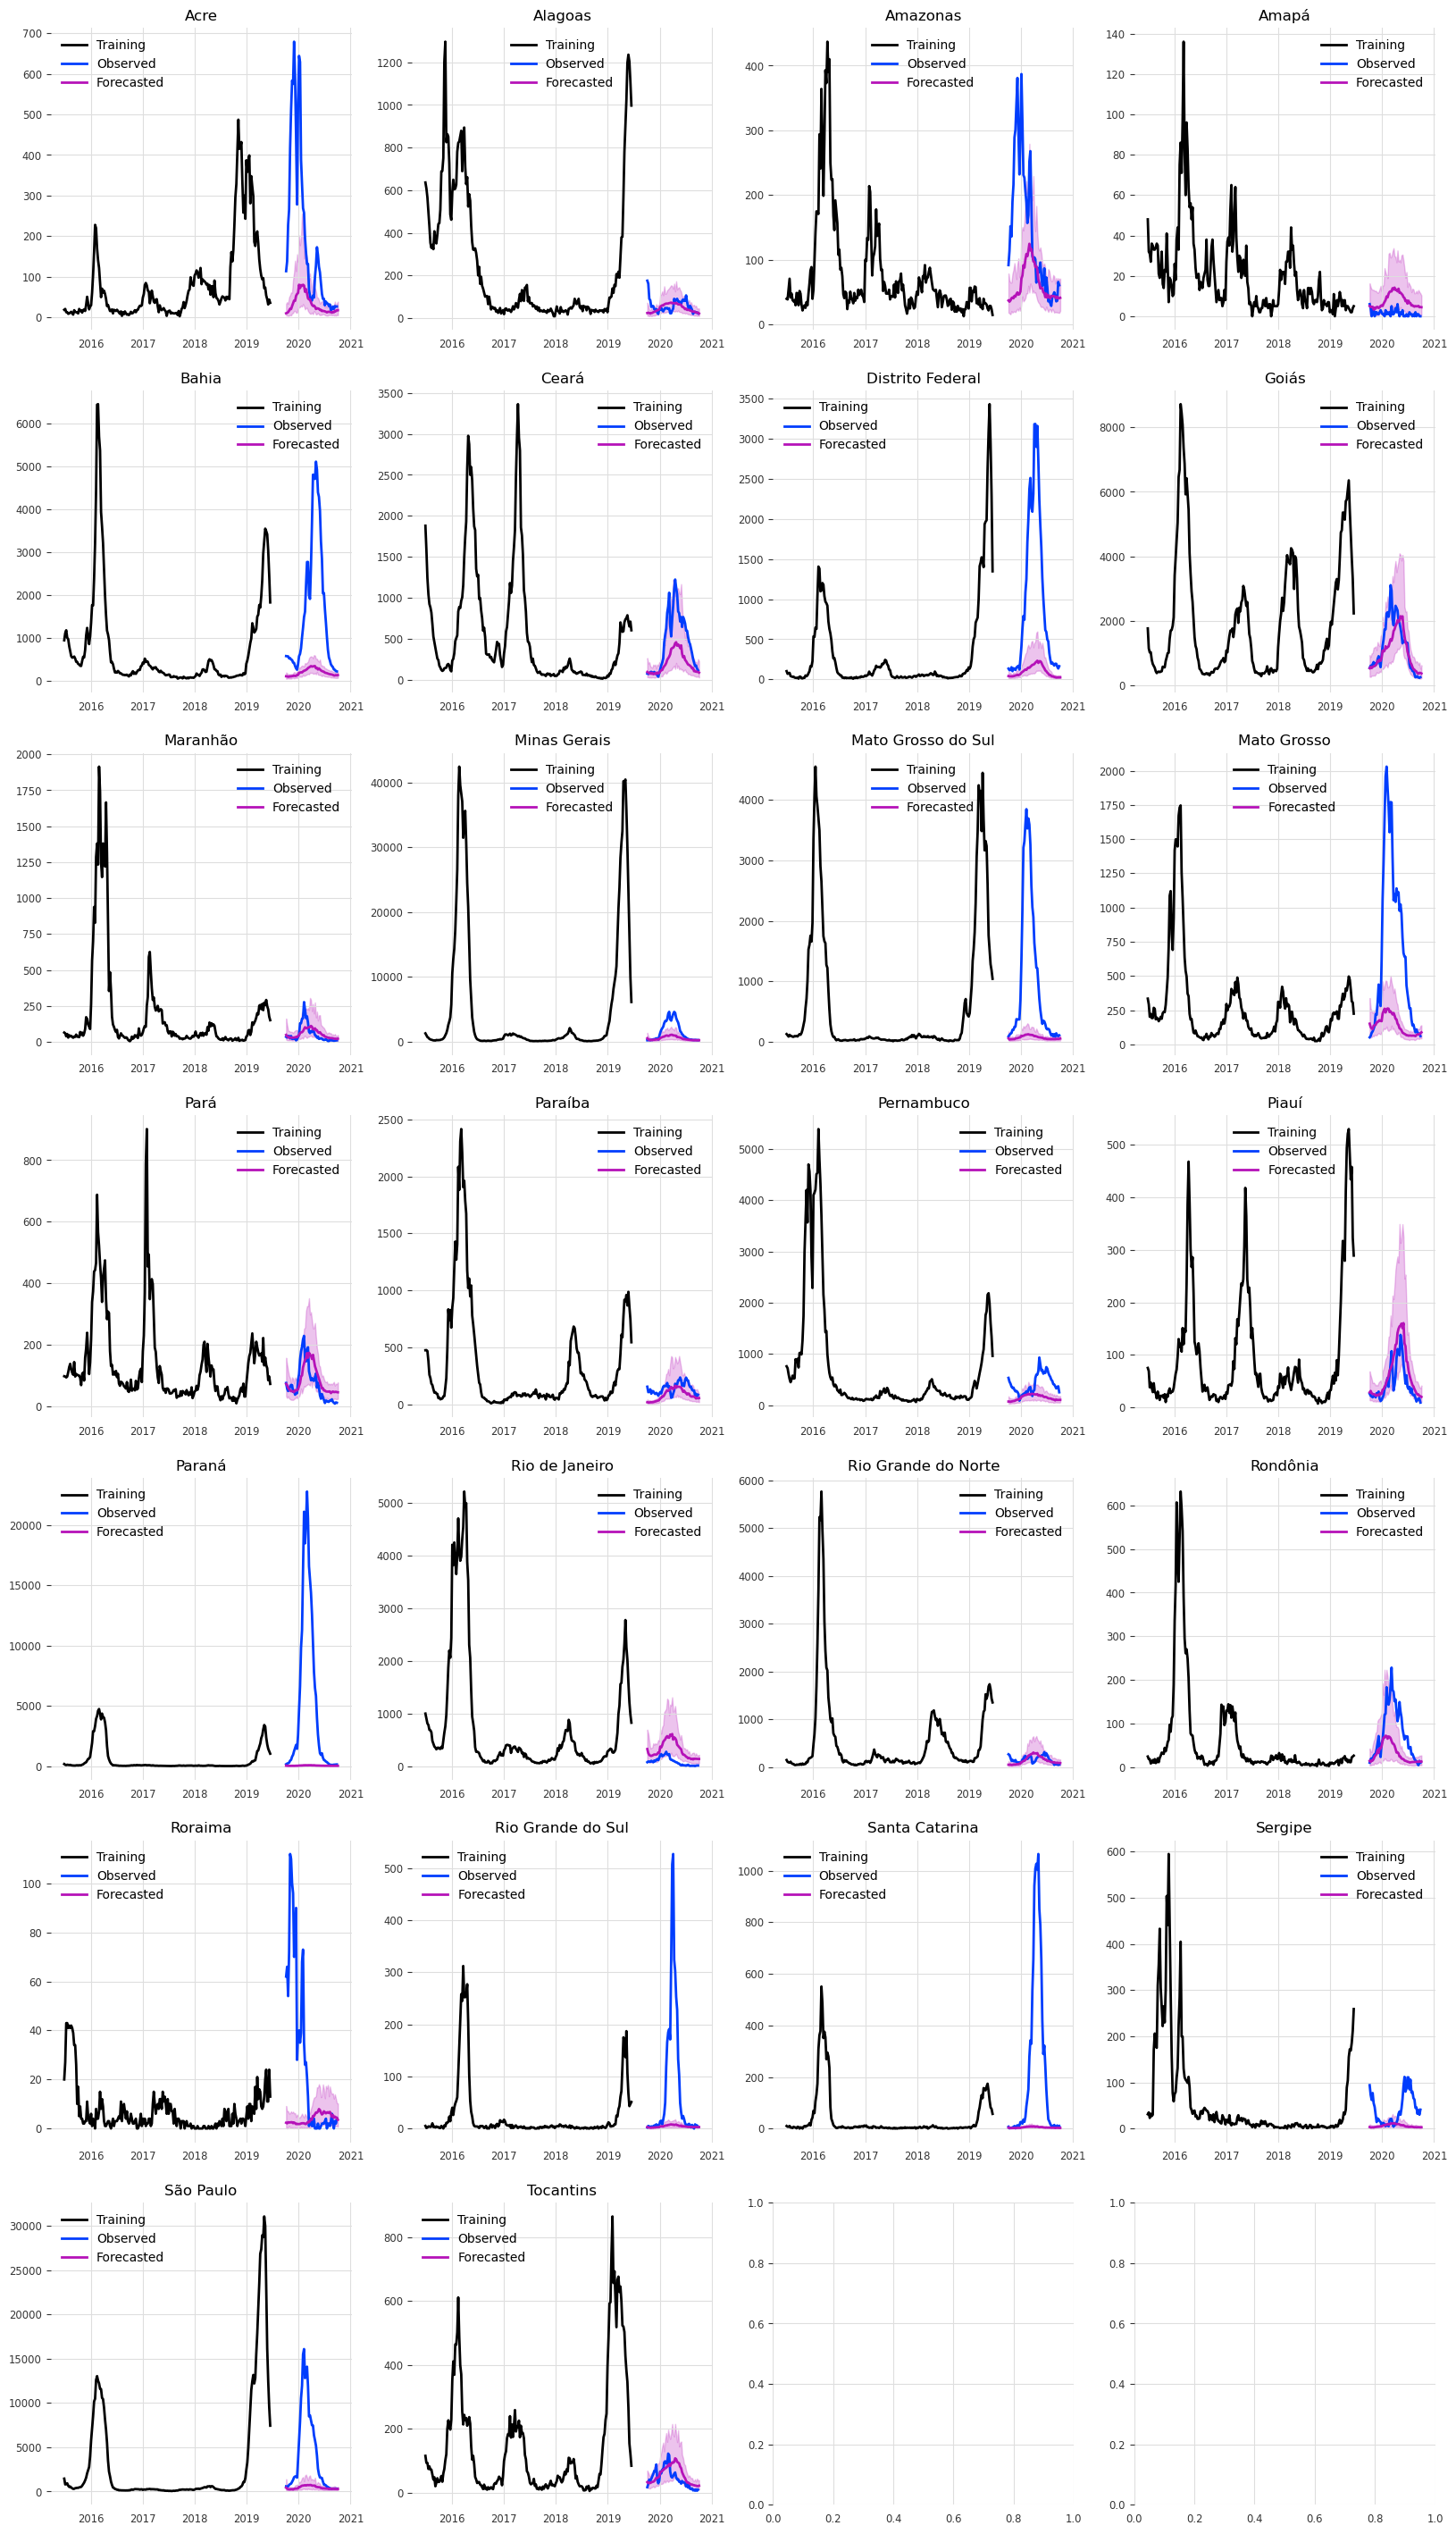

In [30]:
hp.generate_preds_obs_den_plot(train1b, val1b, val1b_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)

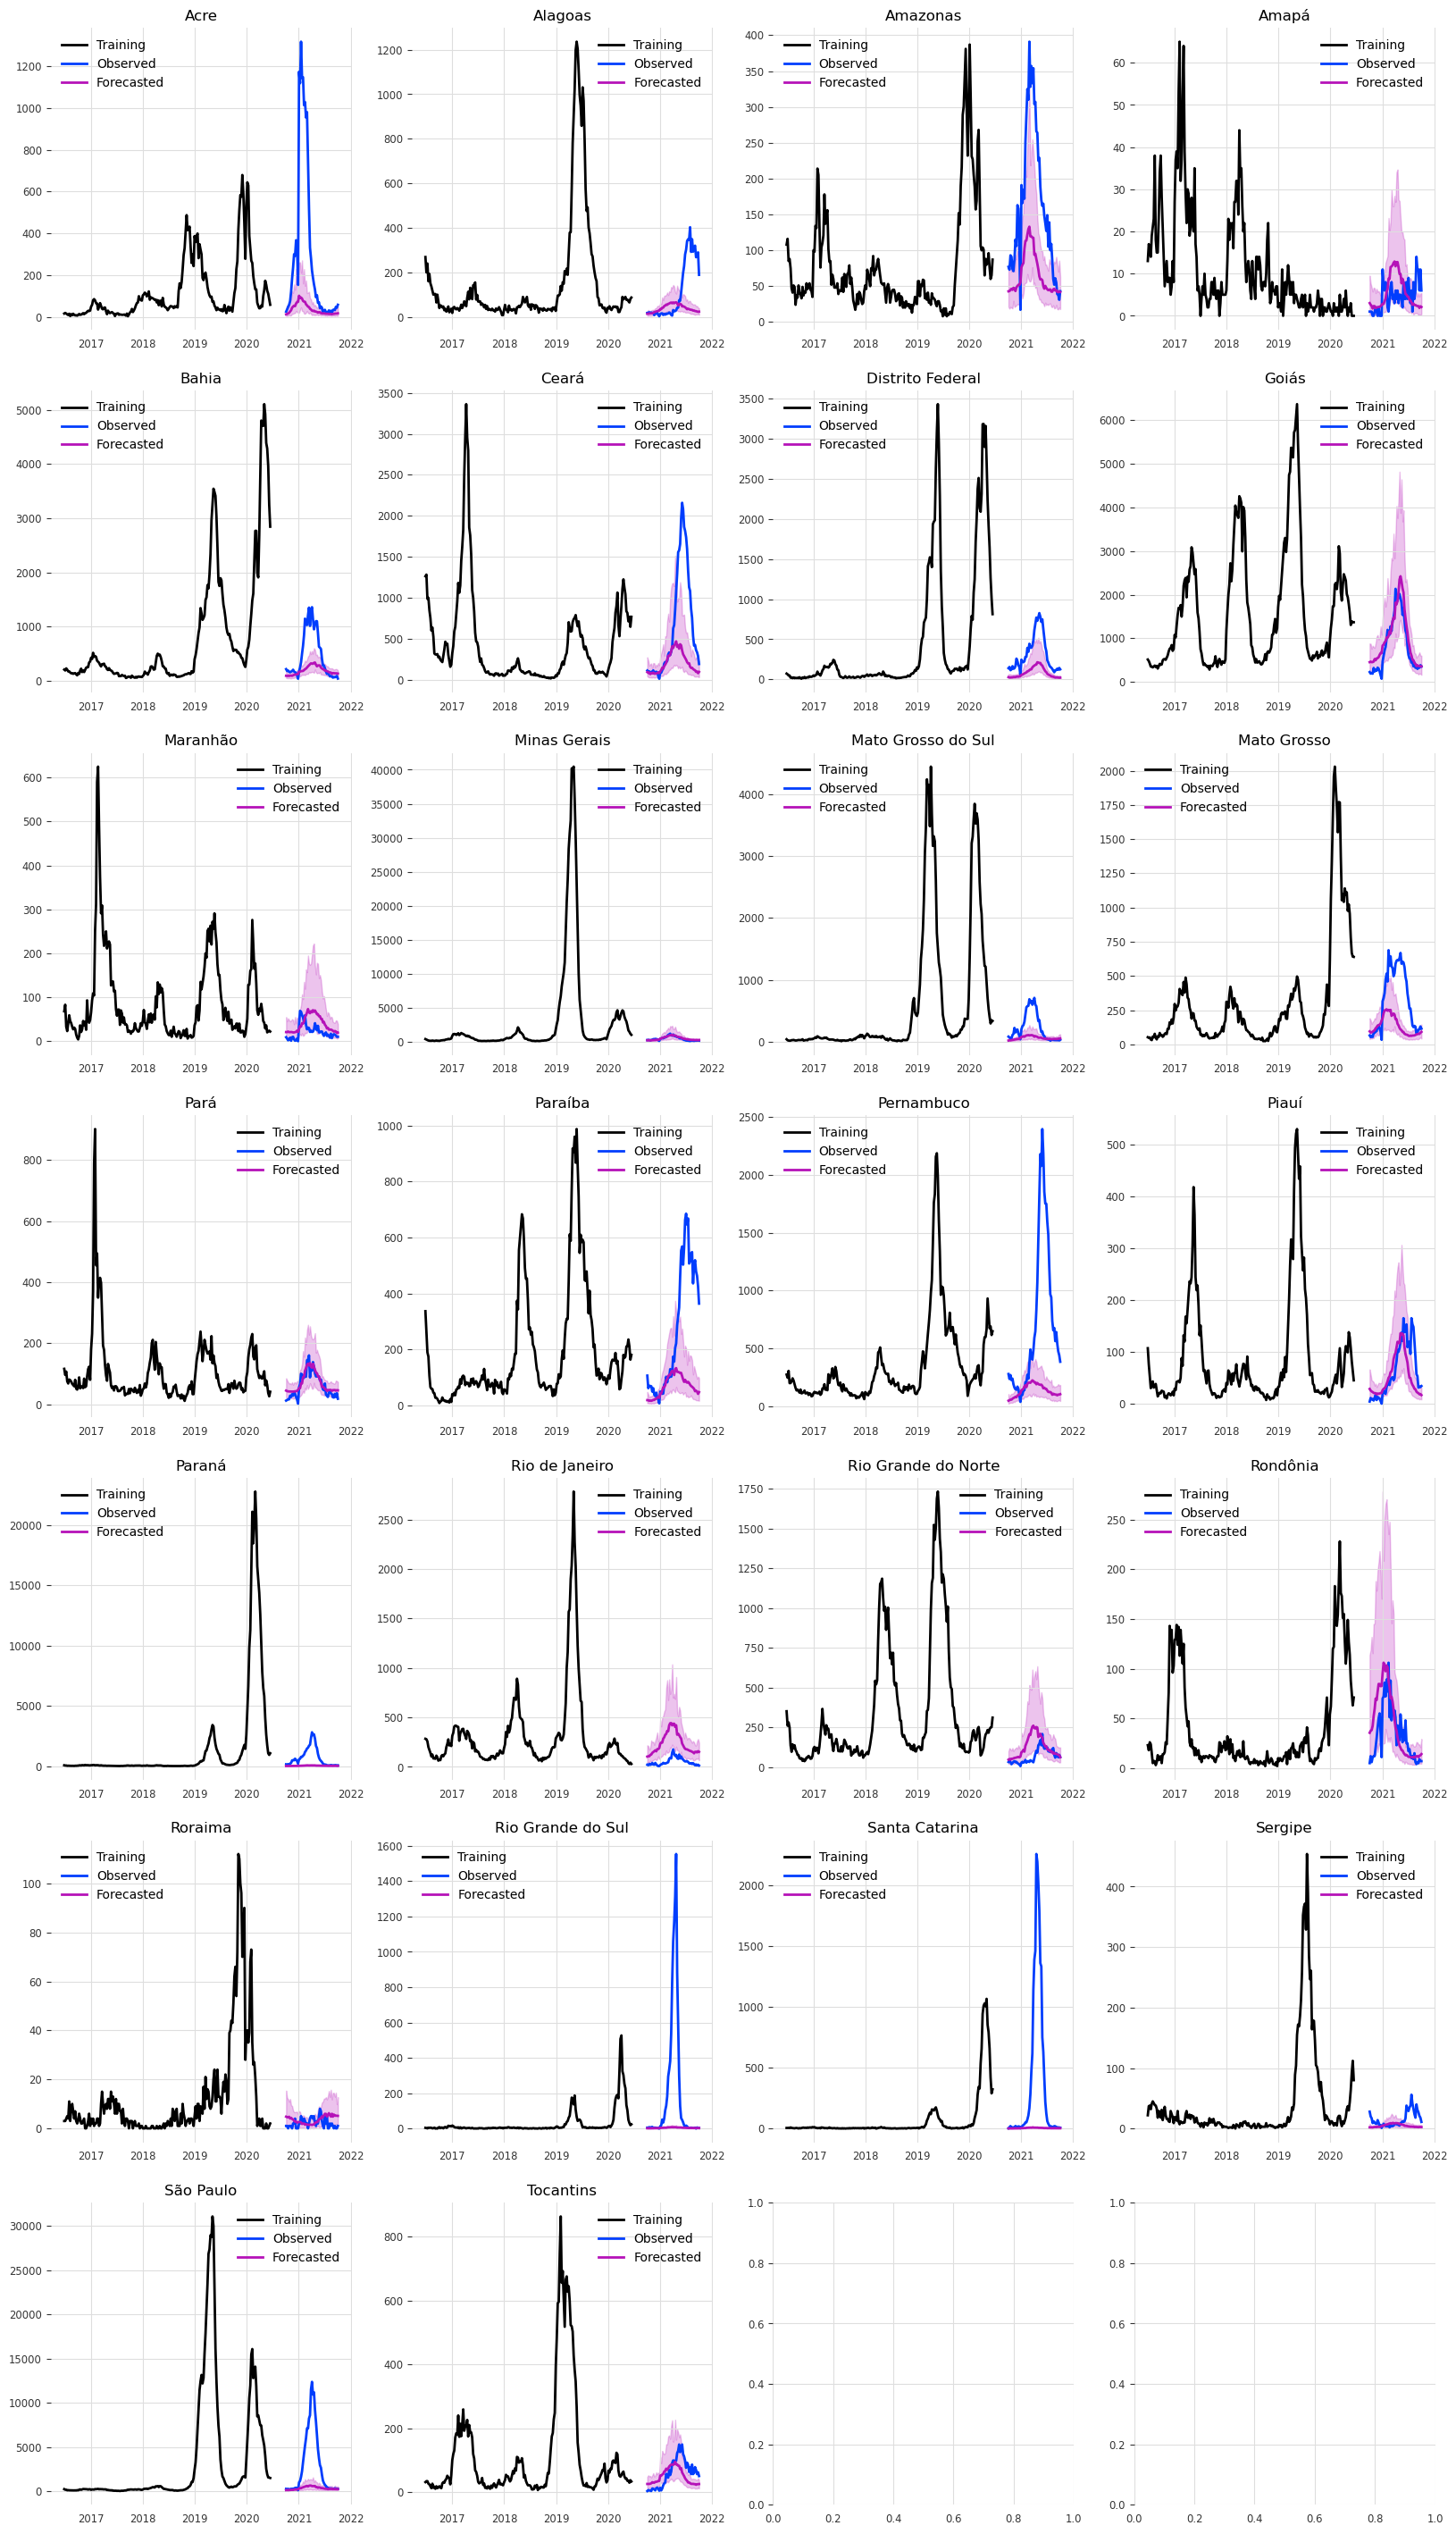

In [31]:
hp.generate_preds_obs_den_plot(train1c, val1c, val1c_predict, uf_list, uf_list, label_list = uf_name_list, train_limit = 208)